In [10]:
# ==============================================================================
# 1. Environment & API Configuration
# ==============================================================================
# Import os module to interact with system environment variables
import os
# Import load_dotenv to read environment variables from a local .env file
from dotenv import load_dotenv

# Load key-value pairs from .env into the environment
load_dotenv()

# Retrieve the Google Gemini API key
GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")

In [11]:
# ==============================================================================
# 2. Import Core Libraries & Dependencies
# ==============================================================================
# TypedDict defines the schema and type structure of the Graph State
from typing import TypedDict

# Import LangGraph components:
# - StateGraph: Core class to define and build the workflow graph
# - START: Virtual node representing graph entry point
# - END: Virtual node representing graph exit/termination
from langgraph.graph import StateGraph, START, END

# Import Google Gemini chat model integration from LangChain
from langchain_google_genai import ChatGoogleGenerativeAI

In [12]:
# ==============================================================================
# 3. Initialize Language Model (LLM)
# ==============================================================================
# Instantiate the Gemini model
# - model: specifies the Google model version
# - temperature: controls randomness (0.3 produces focused, deterministic outputs)
llm = ChatGoogleGenerativeAI(
    model="gemini-3.7-flash",
    temperature=0.3
)

In [13]:
# ==============================================================================
# 4. LLM Connectivity Test
# ==============================================================================
# Invoke the model with a simple prompt to verify API connectivity
response = llm.invoke("Explain LangGraph in one sentence.")

# Print the model's generated text response
print(response.content)

[{'type': 'text', 'text': '**LangGraph** is a framework developed by LangChain that allows you to build complex, stateful, and multi-agent AI applications by modeling workflows as cyclical graphs.', 'extras': {'signature': 'EvcMCvQMARFNMg++sc0kVO5uIc6pU1x6s2vQMWEKP/f/xinPLtdr8Em46F1XuDqr4LZ+Xo/WwEclHtKFDlFn5RQPvSGaL3eQIYjRb9usuVKDaOGE9EncGtars8bS4wNkTyAiz7XyV5ptZLtYkw5fcbwBe8kurOU3rSic/XJusLyOTH+r4iNM/fAz5tOT/aDe9bnIuA6VSloY7KhMltJ5guOS8dyrKpabAp13H0vDefIog3m3QcqVjfqrPxRX/Xvsgi5RoZGajXvVBKfzgOe8HyXipOsit9A556qXa7niuZ4VFMOhLrojbRfdrOwDklKcAe3bnfLS8377EpUfsH0lxTvK9CBBK9SGlxcURvgbSiRNp/6qgZGa9GCTHVZvlgMBbVlfIrKMJGbjjZOAn1jF9CFs/Bs8DrkcsZaz3tN8ELOU4BSiAbyiLnx+Gk8x+tZkysZkSSOK0sePIZFAsbqcdxe/I6fMkpBmA+VG0Y+e8ngE5ZUiGK8MkoZaJwb7Ks39s7H5vi6q0YAPWUVWqL4z/9l1v6DMK8aUp13WIK9BioTy4TzRyswwYkOcc3thtktVYhUPhcf2e5M7nNp0i/qJScoP7TCXu6WrFn1zKLFERU4gRUcfaIcnRdzo+kr6UZh1t7JJiIZGU8Sj3NO60AOd9Xu2qc1YGeK122UuW1lKb4LpWt3t/yPYH/lq/OM5AXKxe+T8kcmBXThEXfIC/+YenPiFqaZ3mJes/eAY2dBOfO06sWsNzVW6ycOFeQm7Deh8ryqxtZV2

In [14]:
# ==============================================================================
# 5. Define Workflow State Schema
# ==============================================================================
# In LangGraph, the State acts as a central data store passed between nodes.
# WorkflowState defines all the keys accessible and modifiable throughout the workflow:
# - input_text: Raw input text supplied by the user
# - summary: Intermediate summary produced by the summarize node
# - improved_text: Polished output produced by the improve node
class WorkflowState(TypedDict):
    input_text: str
    summary: str
    improved_text: str

In [15]:
# ==============================================================================
# 6. Define Node 1: Summarize Node
# ==============================================================================
# A node is a Python function that receives the current State and returns updates.
def summarize_node(state: WorkflowState):
    
    # Construct a prompt requesting a concise summary of the input text
    prompt = f"""
    Summarize the following text clearly and concisely.

    Text:
    {state["input_text"]}
    """

    # Invoke the LLM with the prompt
    response = llm.invoke(prompt)

    # Return a dictionary updating the 'summary' key in State
    return {
        "summary": response.content
    }

In [16]:
# ==============================================================================
# 7. Unit Test: Summarize Node Independently
# ==============================================================================
# Create a sample state dictionary to test summarize_node in isolation
test_state = {
    "input_text": """
    Artificial intelligence is transforming industries by enabling machines
    to perform tasks that previously required human intelligence.
    AI is used in healthcare, education, finance, transportation,
    and many other areas. Machine learning models can
    analyze large amounts of data and identify patterns that humans may
    not easily detect.
    """
}

# Execute summarize_node directly
result = summarize_node(test_state)

# Display the node's output dictionary
print(result)

{'summary': [{'type': 'text', 'text': '**Summary:** \n\nArtificial intelligence is transforming diverse industries—including healthcare, finance, and transportation—by using machine learning to analyze large datasets, detect complex patterns, and perform tasks that traditionally required human intelligence.', 'extras': {'signature': 'EqENCp4NARFNMg9ChXMoEm+Pe3oyhtK0jiexn1DptnCrCFMiDVEclVPJ3uJxS4u2ST/suf/9J2WoSM57Kqw6JmFbvRnQ4U9iweW53wxo6L7Hl0Km2AYMDeMV7nY6T2O2USD3CQT70xmCjMk6SU4oM52yqi1ODKDoeThx8PhW2VT+JP/X7xWpTxvJQkr+f1H2ABRiKN0IALp0LASggecfAsvPEtwN9uYww4yzgWN70EotWbxJ3bhI5cFTMT2nXseCdLOvuYGKtw/FRYUC4df7qUQcEX54k/ifPRgVyOaNOewlOTeHx3k+/dCAFpGzcaYuvZI85zDoUqk3+DAOdbLk6gZPE1oh0X+nKq9DTTlTS2yhZBfcCZ913EWt4v+LOllpF4qr302bODVo/KZKPqnvc0RSot0XcaMBJtHZjaRLRUBtjcEDO8hEMQIVV/HxY9UlOcsAkqiK8aO0MiYnKwgWu1esQkNvOEPRmfbR+YuyDCbxyOxMx0Qo/KZ/Wu25I6UYg58QaPIpDSqxavzXqvzKYGKeYiwXskzmNQM3odnNQPrZN/0/N59RIHLm20mkDpPwnWZxgqlnhnvmMYy7dfTQvURFIGaw/5SPWD9tuqtnAyYvv/UeConFGYlKtb3xpOEXd5LC6ksTofqTE492Sr3UkDag

In [17]:
# ==============================================================================
# 8. Define Node 2: Improve Node
# ==============================================================================
# This node takes the 'summary' generated by the previous step and polishes it.
def improve_node(state: WorkflowState):

    # Construct a prompt instructing the LLM to refine and polish the summary
    prompt = f"""
    Improve the following summary.

    Make it:

    - Clear
    - Professional
    - Concise
    - Easy to understand

    Summary:
    {state["summary"]}
    """

    # Invoke the LLM with the refinement prompt
    response = llm.invoke(prompt)

    # Return a dictionary updating the 'improved_text' key in State
    return {
        "improved_text": response.content
    }

In [18]:
# ==============================================================================
# 9. Unit Test: Improve Node Independently
# ==============================================================================
# Create a sample state dictionary to test improve_node in isolation
test_state = {
    "summary": "AI is changing industries and helping machines perform intelligent tasks."
}

# Execute improve_node directly
result = improve_node(test_state)

# Display the node's output dictionary
print(result)

{'improved_text': [{'type': 'text', 'text': 'Here are a few ways to improve the summary, depending on your preferred tone:\n\n**Option 1: Balanced & Professional (Recommended)**\n> "Artificial intelligence is transforming industries by enabling machines to perform complex tasks."\n\n**Option 2: Ultra-Concise**\n> "AI is driving industry transformation through advanced automation."\n\n**Option 3: Business-Focused**\n> "AI is revolutionizing industries by empowering machines to handle tasks that require human-like intelligence."\n\n---\n\n### Why this is better:\n* **"Transforming"** or **"Revolutionizing"** is more impactful than "changing."\n* **"Enabling"** is more precise than "helping."\n* Replaces the slightly repetitive phrasing of "AI helping machines do intelligent tasks" with clearer concepts like **"complex tasks"** or **"advanced automation."**', 'extras': {'signature': 'EuoQCucQARFNMg+wgY/fPXZ2Bzc6jL6ga3NF7G25jGYQcgUc+8mNHbJ+8617anUOFpg+dEgRs2UKD9wPdl2uMTnrN7GN+AyPWdkcFtLdLS

In [19]:
# ==============================================================================
# 10. Initialize StateGraph
# ==============================================================================
# Create a StateGraph initialized with the WorkflowState schema.
# This serves as the blueprint for our multi-step workflow.
workflow = StateGraph(WorkflowState)

In [20]:
# ==============================================================================
# 11. Register Nodes in the Graph
# ==============================================================================
# Register summarize_node with the unique identifier "summarize"
workflow.add_node("summarize", summarize_node)

# Register improve_node with the unique identifier "improve"
workflow.add_node("improve", improve_node)

In [21]:
# ==============================================================================
# 12. Define Sequential Edges (Control Flow)
# ==============================================================================
# Connect START (entry point) -> "summarize" node
workflow.add_edge(START, "summarize")

# Connect "summarize" node output -> "improve" node input
workflow.add_edge("summarize", "improve")

# Connect "improve" node output -> END (exit point)
workflow.add_edge("improve", END)

In [22]:
# ==============================================================================
# 13. Compile the Workflow
# ==============================================================================
# Compiling validates the graph structure and returns an executable Runnable app.
app = workflow.compile()

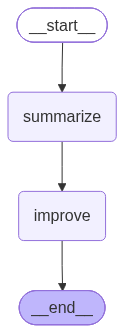

In [23]:
# ==============================================================================
# 14. Visualize Workflow Architecture
# ==============================================================================
# Import display utilities from IPython
from IPython.display import Image, display

# Render and display the workflow topology using Mermaid PNG generator
display(
    Image(
        app.get_graph().draw_mermaid_png()
    )
)

In [24]:
# ==============================================================================
# 15. Execute the Complete Sequential Workflow
# ==============================================================================
# Define the input text to be processed through the workflow
input_text = """
Artificial intelligence is transforming many industries by enabling
machines to perform tasks that previously required human intelligence.
AI systems are now being used in healthcare, education, finance,
transportation, and many other fields. Machine learning models can
analyze large amounts of data and identify patterns that humans may
not easily detect.
"""

# Initialize the state dictionary with the required 'input_text' field
initial_state = {
    "input_text": input_text
}

# Run the complete workflow (START -> summarize -> improve -> END)
result = app.invoke(initial_state)

# Display the final state containing input_text, summary, and improved_text
result

{'input_text': '\nArtificial intelligence is transforming many industries by enabling\nmachines to perform tasks that previously required human intelligence.\nAI systems are now being used in healthcare, education, finance,\ntransportation, and many other fields. Machine learning models can\nanalyze large amounts of data and identify patterns that humans may\nnot easily detect.\n',
 'summary': [{'type': 'text',
   'text': 'Artificial intelligence is transforming diverse industries—including healthcare, finance, and transportation—by automating complex tasks and using machine learning to detect data patterns that humans might miss.',
   'extras': {'signature': 'EvIMCu8MARFNMg9x15Pv0VUcG3YM25Utgais2wtN4RImDAxv1fseH+Ft/7ZAHO/AUpptpp2GKpX1Ai0H4uHqhYnEnvt4Z1a6GoerPhd3Qj6kGoJ6yjx+tlUOxUB+ZqDdnfTyhS0AHEuAAUEiHVlmjfXynMFZFxAQH9ahnl3s6X324T1OtF5+NEFfvQvjVSXb44oUpu6z6iBpPiC5KxcIPLkZomHn5XfsTzmnlPYOF7YNJrM76eq+h9t2Z6SKHEjpoJJUJoNJrwl7TihvgkRFNCUHElPQaPjlD1VCxCP7RuNhFfhCELe2w8XBC3nkKlUDXnjE2hu4vW2

In [25]:
# ==============================================================================
# 16. Format & Inspect Final Workflow Outputs
# ==============================================================================
# Print the original input text
print("ORIGINAL TEXT")
print("-" * 50)
print(result["input_text"])

# Print the intermediate summary generated by Node 1
print("\nSUMMARY")
print("-" * 50)
print(result["summary"])

# Print the final polished text generated by Node 2
print("\nIMPROVED TEXT")
print("-" * 50)
print(result["improved_text"])

ORIGINAL TEXT
--------------------------------------------------

Artificial intelligence is transforming many industries by enabling
machines to perform tasks that previously required human intelligence.
AI systems are now being used in healthcare, education, finance,
transportation, and many other fields. Machine learning models can
analyze large amounts of data and identify patterns that humans may
not easily detect.


SUMMARY
--------------------------------------------------
[{'type': 'text', 'text': 'Artificial intelligence is transforming diverse industries—including healthcare, finance, and transportation—by automating complex tasks and using machine learning to detect data patterns that humans might miss.', 'extras': {'signature': 'EvIMCu8MARFNMg9x15Pv0VUcG3YM25Utgais2wtN4RImDAxv1fseH+Ft/7ZAHO/AUpptpp2GKpX1Ai0H4uHqhYnEnvt4Z1a6GoerPhd3Qj6kGoJ6yjx+tlUOxUB+ZqDdnfTyhS0AHEuAAUEiHVlmjfXynMFZFxAQH9ahnl3s6X324T1OtF5+NEFfvQvjVSXb44oUpu6z6iBpPiC5KxcIPLkZomHn5XfsTzmnlPYOF7YNJrM76eq+h9t2Z

In [26]:
# ==============================================================================
# 17. Stream Execution & Inspect Step-by-Step State Transitions
# ==============================================================================
# app.stream() executes the graph step-by-step, yielding output as each node finishes
for step in app.stream(initial_state):
    # 'step' contains a dictionary of the state updates made by the completed node
    print(step)
    print("-" * 80)

{'summarize': {'summary': [{'type': 'text', 'text': '**Summary:**\n\nArtificial intelligence is transforming various industries—including healthcare, finance, and transportation—by automating tasks that once required human intelligence and using machine learning to uncover complex patterns in vast datasets.', 'extras': {'signature': 'EvsNCvgNARFNMg9eLubpgj0rXjyhhOZUWG2uaPP1B2hvqqEHRvZ05fozFum86xJ3GRY4uWcWIQlWBBM9Ybkd/CnMMklt7lyN9ZqSpBvx321OD+YzNbketdCq5cY66z9diELmqbwy+U+CE+5Iu6fxUtha3DyT7aGjd+9MMAgfcS9f/ftkLCknHznHWhrDano1ZcuOFdIzqgOTFx9K8kcKodPOY49tKnUckQSUDZdatbs51v1lH6rrxvIJCEFQFxBEuNygaRRGcY0JBavzNC4k/xdySaFUD5LNeYzZ6Q70wjFgd3aFwzKI0+ti3mkluDknGTWLG3Niv0iiRUE/2XNyT+h3fRpqmjd6j9WaMlxBSrNztDW77yGCNlRN/mNqqJpMi359F5O380QUET6PiM5+wiPxWmjnAvndYXEt7uCxeRqYXWGHpx9tQnwdSbOCDxagM71WY8xxUG6HGCczKaB7Mp1neuy5S923IPQbrVqcQHfw1xsl7udifJLVrXnCMERvzWnhPgX6UhsDkfEZVUnnxUigSGf2IHPANB1DT+gppbyzZaHEORJvVRk6+q86MQQ9g5SflB5iqPv+tk8yxTsLltytQLurRextW40ycP3pmvxywj93i2WTDCclShnmGm3KTUXDVQFAtfOa/XHYQ7ftbZp/